# Homework 7.2 - Task 6

## Failure Analysis

A successful conditioned-generation experiment does not require every output to be good.

Failures are part of the result.

This notebook looks for several distinct problems:

- truncated generation;
- repeated local phrases;
- weak Odyssey bigram support;
- surface theme-word conditioning without unboosted thematic evidence;
- low probability under the base Odyssey model;
- fluent direct LLM output that is not a quotation from the target corpus.

No generated sentence is grammatically repaired before evaluation.

## 1. Important interpretation limits

The statistical generator receives only a theme label.

It does not receive the full logical proposition of the Marcus passage.

Therefore this project does not define a semantic accuracy score for source-meaning preservation.

For example, the theme `anger` does not tell the model whether the Marcus passage praises anger, condemns anger, or counsels restraint.

A rise in words such as `wrath` is therefore evidence of lexical conditioning, not evidence of ethical or propositional preservation.

In [1]:
from pathlib import Path
from collections import Counter
import json
import math
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw7_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw7_2"

generations = pd.read_csv(
    DATA_DIR
    / "task3_statistical_generations.csv"
)

display_examples = pd.read_csv(
    DATA_DIR
    / "task3_fixed_display_examples.csv"
)

llm_outputs = pd.read_csv(
    DATA_DIR
    / "task4_direct_llm_outputs.csv"
)

task5_metrics = pd.read_csv(
    DATA_DIR
    / "task5_per_sentence_metrics.csv"
)

design = json.loads(
    (
        DATA_DIR
        / "task1_fixed_experiment_design.json"
    ).read_text(
        encoding="utf-8"
    )
)

with open(
    DATA_DIR
    / "task2_odyssey_ngram_model.pkl",
    "rb",
) as handle:
    model = pickle.load(
        handle
    )

odyssey_text = (
    DATA_DIR
    / "odyssey_butler_body.txt"
).read_text(
    encoding="utf-8"
)

THEMES = design[
    "themes"
]

rewarded_words = model[
    "rewarded_words_in_vocab"
]

probe_words = model[
    "probe_words_in_vocab"
]

## 2. Base Odyssey model probability

To assess target-model compatibility, compute the interpolated probability assigned by the unconditioned Odyssey model to each generated next word.

For an output with words $w_1, ..., w_n$, the mean negative log-likelihood averages the negative log probabilities of the transitions that actually occurred. The end marker is included only when the generator emitted the end marker. A sequence cut off by the 30-word limit is not assigned an artificial end transition.

Lower values mean that the observed generated sequence is more probable under the unconditioned Odyssey model.

This is a statistical target-style diagnostic. It is not a complete measure of literary quality.

In [2]:
unigram = model[
    "unigram"
]

bigram = model[
    "bigram"
]

trigram = model[
    "trigram"
]

weights = model[
    "interpolation_weights"
]

unigram_total = float(
    sum(
        unigram.values()
    )
)


def tokenize(text):
    return re.findall(
        r"[A-Za-z]+(?:'[A-Za-z]+)?",
        str(text).lower(),
    )


def counter_probability(
    counter,
    word,
):
    total = sum(
        counter.values()
    )

    if total <= 0:
        return 0.0

    return (
        counter.get(
            word,
            0
        )
        / total
    )


def base_probability(
    previous_two,
    previous_one,
    word,
):
    components = []
    component_weights = []

    if previous_two in trigram:
        components.append(
            counter_probability(
                trigram[
                    previous_two
                ],
                word,
            )
        )

        component_weights.append(
            weights[
                "trigram"
            ]
        )

    if previous_one in bigram:
        components.append(
            counter_probability(
                bigram[
                    previous_one
                ],
                word,
            )
        )

        component_weights.append(
            weights[
                "bigram"
            ]
        )

    components.append(
        unigram.get(
            word,
            0
        )
        / unigram_total
    )

    component_weights.append(
        weights[
            "unigram"
        ]
    )

    component_weights = np.asarray(
        component_weights,
        dtype=float,
    )

    component_weights = (
        component_weights
        / component_weights.sum()
    )

    return float(
        np.dot(
            component_weights,
            np.asarray(
                components,
                dtype=float,
            ),
        )
    )


def sentence_nll(text, stopped_by_end_marker):
    tokens = tokenize(
        text
    )

    sequence = (
        ["<s>", "<s>"]
        + tokens
    )

    if bool(stopped_by_end_marker):
        sequence = sequence + ["</s>"]

    log_probabilities = []

    for i in range(
        2,
        len(sequence),
    ):
        probability = base_probability(
            (
                sequence[i - 2],
                sequence[i - 1],
            ),
            sequence[i - 1],
            sequence[i],
        )

        probability = max(
            probability,
            1e-15,
        )

        log_probabilities.append(
            math.log(
                probability
            )
        )

    if not log_probabilities:
        return float("nan")

    return float(
        -np.mean(
            log_probabilities
        )
    )


## 3. Failure flags

The thresholds below are fixed and descriptive.

A generated sentence is flagged for:

- `truncated`: it reached the 30-word limit;
- `high_internal_repetition`: repeated-bigram fraction at least 0.20;
- `low_bigram_coverage`: fewer than 70 percent of adjacent word pairs occur in the Odyssey corpus;
- `surface_only_theme_signal`: at least one rewarded word occurs but no unboosted probe word occurs.

The final flag does not prove semantic failure. It marks an output where the only lexical evidence of the theme comes from the words that were directly rewarded.

In [3]:
detail = (
    generations.merge(
        task5_metrics[
            [
                "theme",
                "mode",
                "sample_index",
                "seed",
                "repeated_bigram_fraction",
                "odyssey_bigram_coverage",
            ]
        ],
        on=[
            "theme",
            "mode",
            "sample_index",
            "seed",
        ],
        how="left",
        validate="one_to_one",
    )
)

detail[
    "base_odyssey_nll"
] = [
    sentence_nll(
        text,
        stopped_by_end_marker,
    )
    for text, stopped_by_end_marker
    in zip(
        detail["text"],
        detail["stopped_by_end_marker"],
    )
]

detail[
    "flag_truncated"
] = detail[
    "truncated"
].astype(bool)

detail[
    "flag_high_internal_repetition"
] = (
    detail[
        "repeated_bigram_fraction"
    ]
    >= 0.20
)

detail[
    "flag_low_bigram_coverage"
] = (
    detail[
        "odyssey_bigram_coverage"
    ]
    < 0.70
)

detail[
    "flag_surface_only_theme_signal"
] = (
    (
        detail[
            "reward_hits"
        ] > 0
    )
    & (
        detail[
            "probe_hits"
        ] == 0
    )
)

detail_path = (
    DATA_DIR
    / "task6_failure_flags.csv"
)

detail.to_csv(
    detail_path,
    index=False,
)

print(
    "Saved:",
    detail_path.resolve(),
)

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\data\hw7_2\task6_failure_flags.csv


## 4. Aggregate failure rates

In [4]:
failure_summary = (
    detail.groupby(
        [
            "theme",
            "mode",
        ]
    )
    .agg(
        samples=(
            "text",
            "size",
        ),
        truncation_rate=(
            "flag_truncated",
            "mean",
        ),
        high_repetition_rate=(
            "flag_high_internal_repetition",
            "mean",
        ),
        low_bigram_coverage_rate=(
            "flag_low_bigram_coverage",
            "mean",
        ),
        surface_only_theme_signal_rate=(
            "flag_surface_only_theme_signal",
            "mean",
        ),
        mean_base_odyssey_nll=(
            "base_odyssey_nll",
            "mean",
        ),
        median_base_odyssey_nll=(
            "base_odyssey_nll",
            "median",
        ),
    )
    .reset_index()
)

summary_path = (
    DATA_DIR
    / "task6_failure_summary.csv"
)

failure_summary.to_csv(
    summary_path,
    index=False,
)

print(
    failure_summary.to_string(
        index=False
    )
)

       theme          mode  samples  truncation_rate  high_repetition_rate  low_bigram_coverage_rate  surface_only_theme_signal_rate  mean_base_odyssey_nll  median_base_odyssey_nll
       anger   conditioned      500            0.480                   0.0                     0.010                           0.036               2.815881                 2.709323
       anger unconditioned      500            0.494                   0.0                     0.006                           0.012               2.778441                 2.691218
  discipline   conditioned      500            0.486                   0.0                     0.006                           0.020               2.772336                 2.705507
  discipline unconditioned      500            0.452                   0.0                     0.008                           0.004               2.832537                 2.766551
        duty   conditioned      500            0.450                   0.0                     

## 5. Fixed-rule failure examples

Examples are not selected because they are amusing or especially bad.

For each theme, mode, and failure type, display the smallest sample index that satisfies the flag.

If no sample has that failure, no example is displayed for that category.

In [5]:
flag_columns = {
    "truncated": (
        "flag_truncated"
    ),
    "high_internal_repetition": (
        "flag_high_internal_repetition"
    ),
    "low_bigram_coverage": (
        "flag_low_bigram_coverage"
    ),
    "surface_only_theme_signal": (
        "flag_surface_only_theme_signal"
    ),
}

example_rows = []

for theme in THEMES:
    for mode in [
        "unconditioned",
        "conditioned",
    ]:
        subset = (
            detail[
                (
                    detail[
                        "theme"
                    ] == theme
                )
                & (
                    detail[
                        "mode"
                    ] == mode
                )
            ]
            .sort_values(
                "sample_index"
            )
        )

        for failure_name, column in (
            flag_columns.items()
        ):
            failed = subset[
                subset[column]
            ]

            if len(failed) == 0:
                continue

            row = failed.iloc[0]

            example_rows.append({
                "theme": theme,
                "mode": mode,
                "failure_type": (
                    failure_name
                ),
                "sample_index": int(
                    row[
                        "sample_index"
                    ]
                ),
                "seed": int(
                    row[
                        "seed"
                    ]
                ),
                "text": row[
                    "text"
                ],
            })


failure_examples = pd.DataFrame(
    example_rows
)

failure_example_path = (
    DATA_DIR
    / "task6_fixed_failure_examples.csv"
)

failure_examples.to_csv(
    failure_example_path,
    index=False,
)

print(
    failure_examples.to_string(
        index=False
    )
)

       theme          mode              failure_type  sample_index   seed                                                                                                                                                                       text
  discipline unconditioned                 truncated             0  63872                                       So he did was to press forward had to you have said is true force only i am mentes son of maia making a pall this is your age shall.
  discipline unconditioned       low_bigram_coverage           179  64051                                                                                                                                                  He gobbled town end bull.
  discipline unconditioned surface_only_theme_signal           220  64092                           The king of kings may want to sing to turn you out by labour and sorrow he stood his spear and they flocked to fill your belly by begging never.
  discipline   condi

## 6. Are displayed outputs quotations from the Odyssey?

Generated sentences should be labeled as inventions unless a corpus location supports calling them quotations.

The check below normalizes whitespace and case and tests whether a displayed generated sentence appears exactly in the target corpus.

The same check is performed for the direct LLM outputs.

In [6]:
def normalized_sentence(text):
    return re.sub(
        r"\s+",
        " ",
        str(text).lower(),
    ).strip()


odyssey_normalized = (
    normalized_sentence(
        odyssey_text
    )
)

support_rows = []

for row in display_examples.itertuples():
    candidate = normalized_sentence(
        row.text
    )

    support_rows.append({
        "source": (
            "statistical_"
            + row.mode
        ),
        "theme": row.theme,
        "text": row.text,
        "exact_sentence_found_in_odyssey": (
            candidate
            in odyssey_normalized
        ),
    })


for row in llm_outputs.itertuples():
    candidate = normalized_sentence(
        row.response
    )

    support_rows.append({
        "source": (
            "direct_llm"
        ),
        "theme": row.theme,
        "text": row.response,
        "exact_sentence_found_in_odyssey": (
            candidate
            in odyssey_normalized
        ),
    })


corpus_support = pd.DataFrame(
    support_rows
)

support_path = (
    DATA_DIR
    / "task6_displayed_output_corpus_support.csv"
)

corpus_support.to_csv(
    support_path,
    index=False,
)

print(
    corpus_support.to_string(
        index=False
    )
)

                   source        theme                                                                                                                                   text  exact_sentence_found_in_odyssey
statistical_unconditioned   discipline                                                                               I have left at pylos are already urging her to the town.                            False
  statistical_conditioned   discipline                       It was that of ajax who was as fast as he leaned upon his native land showed on the plain was filled with blood.                            False
statistical_unconditioned    mortality                                                                      He was saying and agreed that i father i have twenty geese about.                            False
  statistical_conditioned    mortality                                                           Surely no man and his acceptance let us a mischief but i was in the house a

## 7. Compare target-model NLL by mode

If conditioning strongly rewards theme words that do not fit the current local context, the conditioned output may become less probable under the base Odyssey model.

That would be evidence of a tradeoff between explicit conditioning and target-corpus statistical fluency.

       theme          mode  count     mean   median      std
       anger   conditioned    500 2.815881 2.709323 0.730437
       anger unconditioned    500 2.778441 2.691218 0.641785
  discipline   conditioned    500 2.772336 2.705507 0.642498
  discipline unconditioned    500 2.832537 2.766551 0.663890
        duty   conditioned    500 2.780466 2.698805 0.628991
        duty unconditioned    500 2.775981 2.697811 0.647827
   mortality   conditioned    500 2.751015 2.656134 0.593558
   mortality unconditioned    500 2.815051 2.707934 0.671884
self-command   conditioned    500 2.823516 2.735147 0.640409
self-command unconditioned    500 2.732275 2.660798 0.616409


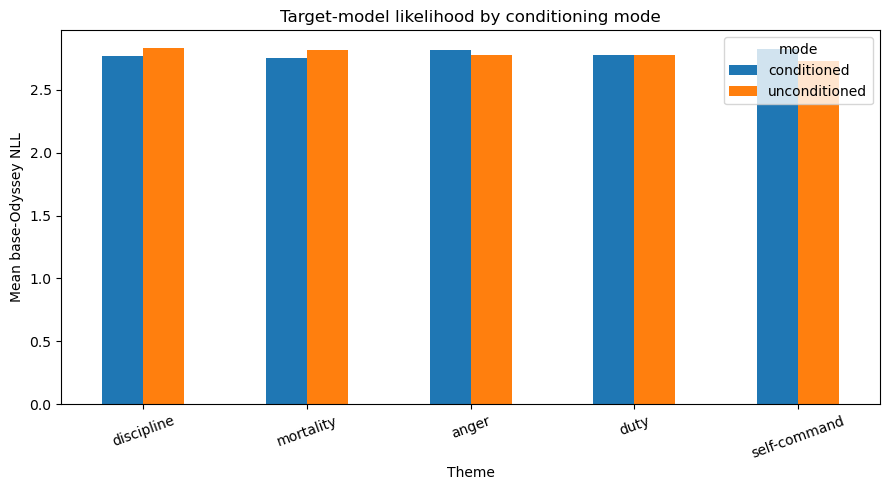

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\result images\hw7_2\task6_base_odyssey_nll.png


In [7]:
nll_summary = (
    detail.groupby(
        [
            "theme",
            "mode",
        ]
    )[
        "base_odyssey_nll"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
        ]
    )
    .reset_index()
)

nll_path = (
    DATA_DIR
    / "task6_base_odyssey_nll_summary.csv"
)

nll_summary.to_csv(
    nll_path,
    index=False,
)

print(
    nll_summary.to_string(
        index=False
    )
)

pivot = (
    nll_summary.pivot(
        index="theme",
        columns="mode",
        values="mean",
    )
    .reindex(
        THEMES
    )
)

pivot.plot(
    kind="bar",
    figsize=(9, 5),
)

plt.xlabel("Theme")
plt.ylabel(
    "Mean base-Odyssey NLL"
)
plt.title(
    "Target-model likelihood by conditioning mode"
)
plt.xticks(rotation=20)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task6_base_odyssey_nll.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 6 Interpretation Guide

The final report should treat the following as separate questions.

### Did the conditioning mechanism work?

Use rewarded-word rates and the many-sample distribution comparison from Task 5.

### Did the output remain statistically compatible with the target corpus?

Use bigram coverage, repetition, truncation, and base-Odyssey NLL.

### Did the output preserve the Marcus passage's meaning?

Do not claim a semantic accuracy score.

The statistical generator receives only a theme label, so the full source proposition is not available to preserve.

### Did the LLM produce a fluent sentence?

Fluency can be discussed qualitatively, but fluency does not make the sentence a quotation from the Odyssey.

The exact-corpus-support check should be used before describing any generated sentence as corpus-supported text.

# Task 6 Conclusion

The failure analysis shows several distinct limitations.

First, the 30-word cutoff is reached often. Across all themes, about 47.9 percent of unconditioned samples and 46.6 percent of conditioned samples are truncated. The generator therefore frequently fails to emit its learned end marker within the requested length limit.

Second, simple local statistics look much better than global sentence quality. Mean Odyssey bigram coverage is about 95.96 percent in both modes, and the high-repetition flag is zero for every theme and mode. Nevertheless, many fixed-rule examples are grammatically awkward or semantically incoherent. High local n-gram compatibility is therefore not evidence of coherent Odyssey-style prose.

Third, conditioning does not create a consistent target-model fluency penalty or benefit. The overall mean base-Odyssey NLL is about 2.787 for unconditioned output and 2.789 for conditioned output, with the direction varying by theme. The main measurable conditioning effect is lexical rather than a general improvement in target-corpus likelihood.

Fourth, surface-only theme signals occur more often after conditioning for several themes, reaching about 10.6 percent for mortality and 11.0 percent for self-command. These flags do not prove semantic failure, but they show cases where the only measured thematic evidence is the vocabulary that was directly rewarded.

Finally, none of the ten displayed statistical outputs or five direct LLM outputs appears as an exact normalized sentence in the Odyssey corpus. They must therefore be labeled as generated inventions, not quotations. The direct LLM sentences are much more fluent qualitatively, but one response per theme is only an illustrative comparison and cannot be treated as a matched statistical benchmark.

The largest conceptual limitation is semantic: the statistical generator receives only a theme label, not the full Marcus proposition. It can imitate surface topic words without knowing whether Marcus praises, condemns, or qualifies that topic. This is especially important for anger, where rewarding words such as `wrath` or `rage` does not preserve a passage that counsels restraint.